# Run the burn2scar baseline model

The baseline U-Net (ResNet-34) in `models/burn2scar-unet-r34` takes one Sentinel-2 Level-1C image and gives every
pixel one of six classes: clear, fresh_burn, old_burn, cloud, cloud shadow and water. It is one of the baselines of
the burn2scar data paper, there to show that the labels can be learned, not tuned to be the best possible model.

This notebook loads it, runs it on random test tiles it never saw in training, draws where it agrees with the mask
and where it doesn't, and shows how to run it on your own images. The first run downloads the weights (98 MB) from
[Hugging Face](https://huggingface.co/neet1797/burn2scar-unet-r34) into the model folder, and each tile it shows
(a few MB).

**Contents:** 1. Load the model · 2. Its scores on the test set · 3. Random test tiles · 4. Where it agrees ·
5. Your own image

In [1]:
import os
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import rasterio
from matplotlib.colors import BoundaryNorm, ListedColormap
from matplotlib.patches import Patch

%config InlineBackend.figure_format = "png"
plt.rcParams.update({"figure.dpi": 100, "font.size": 10, "axes.titlesize": 10, "axes.titlelocation": "left",
                     "axes.spines.top": False, "axes.spines.right": False})

DATASET = "neet1797/burn2scar"                 # burn2scar 3.0 on Hugging Face
LOCAL_ROOT = os.environ.get("BURN2SCAR_ROOT")  # or a folder holding the unzipped Zenodo release
REPO = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "tools").is_dir())


def fetch(path):
    """A file of the release, from LOCAL_ROOT when it is set, else downloaded once from Hugging Face."""
    if LOCAL_ROOT:
        return Path(LOCAL_ROOT) / path
    from huggingface_hub import hf_hub_download
    return Path(hf_hub_download(DATASET, path, repo_type="dataset"))


BANDS = ["B01", "B02", "B03", "B04", "B05", "B06", "B07", "B08", "B8A", "B09", "B10", "B11", "B12"]
# Mask value: (name, colour). Burn age is one hue, darker when more recent, as in the paper's figures.
CLASSES = {2: ("fresh_burn", "#7f2704"), 3: ("old_burn", "#d9480f"), 7: ("older_burn", "#f5a04a"),
           0: ("clear", "#f1efe8"), 6: ("water", "#2a78d6"), 5: ("cloud shadow", "#25272d"),
           4: ("cloud", "#b4c0ce"), 255: ("no data", "#000000")}
_values = sorted(CLASSES)
MASK_CMAP = ListedColormap([CLASSES[v][1] for v in _values])
MASK_NORM = BoundaryNorm([v - .5 for v in _values] + [_values[-1] + .5], MASK_CMAP.N)
COUNTRY = {"IT": "Italy", "ES": "Spain", "FR": "France", "EL": "Greece"}


def read_tile(row):
    """The 13-band image (reflectance x 10,000) and the mask of one row of the index."""
    with rasterio.open(fetch(row["image_path"])) as src:
        image = src.read()
    with rasterio.open(fetch(row["mask_path"])) as src:
        mask = src.read(1)
    return image, mask


def composite(image, recipe):
    """An RGB picture from three bands, each divided by a fixed reflectance so tiles compare with each other."""
    rgb = np.stack([image[BANDS.index(band)] / 10000 / scale for band, scale in recipe], axis=-1)
    return np.clip(rgb, 0, 1) ** .9


TRUE_COLOUR = (("B04", .28), ("B03", .28), ("B02", .32))
FALSE_COLOUR = (("B12", .40), ("B8A", .50), ("B04", .28))  # burned ground shows red-brown, vegetation green


def show_image(ax, image, mask=None, recipe=FALSE_COLOUR, title=None):
    """Draw a tile; with a mask, outline its burn (fresh and old) in white."""
    ax.imshow(composite(image, recipe), interpolation="bilinear")
    if mask is not None and np.isin(mask, [2, 3]).any():
        ax.contour(np.isin(mask, [2, 3]).astype(float), levels=[.5], colors="white", linewidths=.9)
    ax.set_axis_off()
    if title:
        ax.set_title(title)


def show_mask(ax, mask, title=None):
    ax.imshow(mask, cmap=MASK_CMAP, norm=MASK_NORM, interpolation="nearest")
    ax.set_axis_off()
    if title:
        ax.set_title(title)


def class_legend(fig, values=(2, 3, 7, 0, 6, 5, 4), **kwargs):
    handles = [Patch(facecolor=CLASSES[v][1], edgecolor="#8a8984", linewidth=.5, label=CLASSES[v][0]) for v in values]
    fig.legend(handles=handles, loc="lower center", ncol=len(handles), frameon=False, **kwargs)


import json
import sys

import torch

sys.path.insert(0, str(REPO / "tools"))
from predict import load_model, predict_array, predict_file  # noqa: E402

## 1. Load the model

In [2]:
MODEL = REPO / "models" / "burn2scar-unet-r34"
device = "cuda" if torch.cuda.is_available() else "cpu"
net, config = load_model(MODEL, device)
parameters = sum(p.numel() for p in net.parameters())
print(f"{config['architecture']} with a {config['encoder']} encoder, {parameters / 1e6:.1f} M parameters, on {device}")
print(f"Input: {config['in_channels']} bands, {', '.join(config['bands'])}; reflectance x {config['scale']:,}")
print(f"Output: {', '.join(f'{v} {c}' for v, c in zip(config['mask_values'], config['classes']))}")

/root/projects/burn2scar/.venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Unet with a resnet34 encoder, 24.5 M parameters, on cuda
Input: 13 bands, B01, B02, B03, B04, B05, B06, B07, B08, B8A, B09, B10, B11, B12; reflectance x 10,000
Output: 0 clear, 2 fresh_burn, 3 old_burn, 4 cloud, 5 shadow, 6 water


## 2. Its scores on the test set

From `metrics.json`: the test set of the main split, scored over every test tile. This model is the seed with the
median fresh-burn F1 of five, so it is a typical run, not the luckiest. Fresh burn is scored against clear, old_burn
and water; cloud, shadow, older_burn and no data are left out.

In [3]:
metrics = json.loads((MODEL / "metrics.json").read_text())
seeds = metrics["seeds"]
mine = next(s for s in seeds if s["seed"] == metrics["model_seed"])
rows = {
    "Fresh burn F1": lambda s: s["fresh"]["burnt_f1"],
    "Fresh burn precision": lambda s: s["fresh"]["burnt_precision"],
    "Fresh burn recall": lambda s: s["fresh"]["burnt_recall"],
    "Fresh and old burn together, F1": lambda s: s["burnt"]["burnt_f1"],
    "Fresh vs old, right age": lambda s: s["fresh_old_accuracy"],
}
pd.DataFrame({
    "this model (%)": {name: round(get(mine) * 100, 2) for name, get in rows.items()},
    f"{len(seeds)} seeds, mean (%)": {name: round(np.mean([get(s) for s in seeds]) * 100, 2) for name, get in rows.items()},
    "sd": {name: round(np.std([get(s) for s in seeds], ddof=1) * 100, 2) for name, get in rows.items()},
}).rename_axis(f"{metrics['test_tiles']:,} test tiles")

,this model (%),"5 seeds, mean (%)",sd
"5,420 test tiles",,,
Fresh burn F1,81.20,80.78,1.17
Fresh burn precision,75.27,74.26,2.53
Fresh burn recall,88.13,88.64,1.05
"Fresh and old burn together, F1",75.30,74.85,1.06
"Fresh vs old, right age",95.85,95.89,0.55


## 3. Random test tiles

Six tiles drawn at random, with a fixed seed, from the test set of the main split. The test tiles lie in 0.5°
blocks the model never trained on. Change `random_state` for others.

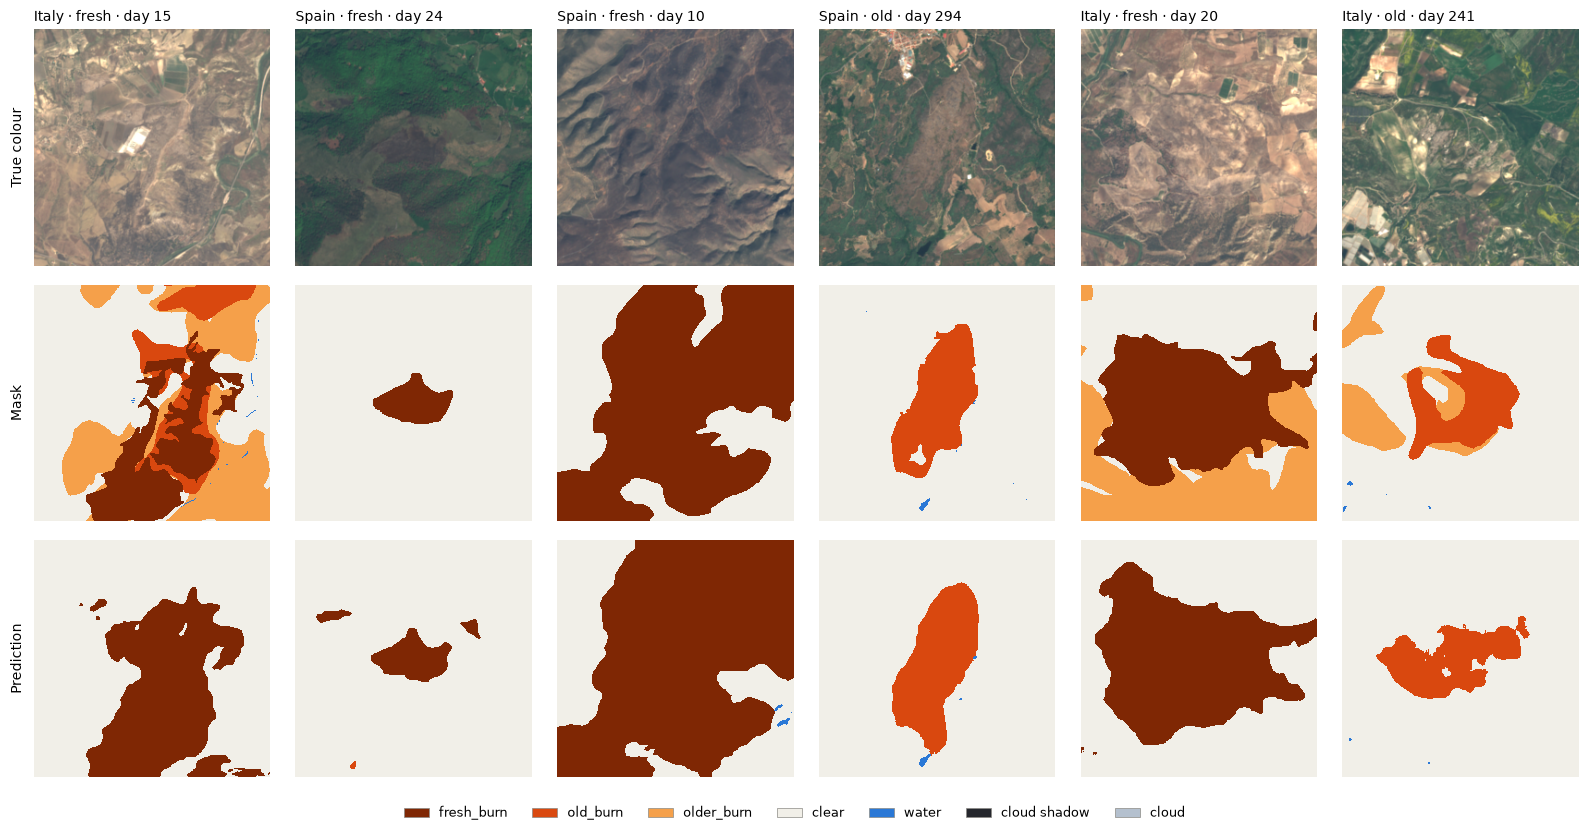

In [4]:
index = pd.read_csv(fetch("index.csv"), low_memory=False)
test = index[(index["split"] == "test") & (index["frac_nodata"] < .02)]
picked = test.sample(6, random_state=5)
results = []
for _, row in picked.iterrows():
    image, mask = read_tile(row)
    results.append((row, image, mask, predict_array(net, config, image, device)))

fig, axes = plt.subplots(3, 6, figsize=(16, 8.4))
for column, (row, image, mask, predicted) in zip(axes.T, results):
    show_image(column[0], image, recipe=TRUE_COLOUR, title=f"{COUNTRY[row['country']]} · {row['window']} · day {row['age_days']:.0f}")
    show_mask(column[1], mask)
    show_mask(column[2], predicted)
for ax, label in zip(axes[:, 0], ("True colour", "Mask", "Prediction")):
    ax.text(-.04, .5, label, transform=ax.transAxes, rotation=90, ha="right", va="center", fontsize=10)
class_legend(fig, fontsize=9)
fig.subplots_adjust(left=.02, right=.995, top=.95, bottom=.06, wspace=.04, hspace=.08)
plt.show()

## 4. Where it agrees

Fresh burn only, the class an onboard alert is about: found (in the mask and predicted), missed (in the mask, not
predicted) and false alarm (predicted, not in the mask). Pixels the scores leave out (cloud, shadow, older_burn and
no data) are grey.

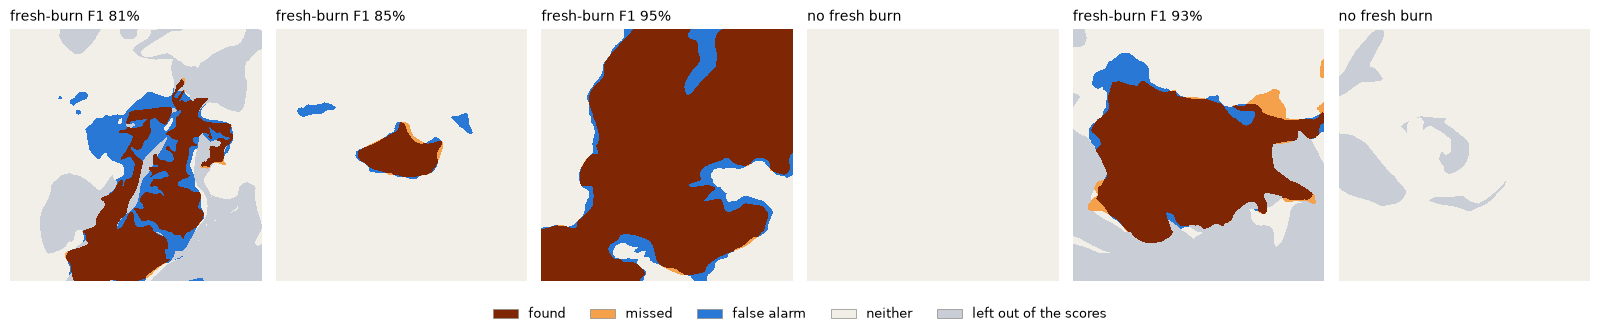

,tile,fresh burn in mask (px),predicted (px),found (px)
0,effis_561509/2026-07-20T10-00-21,12846,18607,12738
1,effis_48321/2021-04-23T11-09-10,2892,3479,2714
2,effis_225795/2024-02-19T11-01-03,43415,47463,43301
3,effis_278911/2026-06-06T11-20-27,0,0,0
4,effis_562145/2026-08-09T10-00-19,25066,26148,23869
5,effis_278603/2026-04-11T10-00-17,0,0,0


In [5]:
AGREE = ListedColormap(["#f1efe8", "#7f2704", "#f5a04a", "#2a78d6", "#c9ced6"])
fig, axes = plt.subplots(1, 6, figsize=(16, 3.4))
table = []
for ax, (row, image, mask, predicted) in zip(axes, results):
    scored = np.isin(mask, [0, 2, 3, 6])
    truth, guess = (mask == 2) & scored, (predicted == 2) & scored
    picture = np.zeros(mask.shape, int)
    picture[truth & guess], picture[truth & ~guess], picture[~truth & guess], picture[~scored] = 1, 2, 3, 4
    ax.imshow(picture, cmap=AGREE, vmin=-.5, vmax=4.5, interpolation="nearest")
    ax.set_axis_off()
    hits, labelled, flagged = int((truth & guess).sum()), int(truth.sum()), int(guess.sum())
    f1 = 2 * hits / (labelled + flagged) if labelled + flagged else np.nan
    ax.set_title(f"fresh-burn F1 {f1:.0%}" if labelled + flagged else "no fresh burn")
    table.append({"tile": row["tile_id"], "fresh burn in mask (px)": labelled, "predicted (px)": flagged, "found (px)": hits})
fig.legend(handles=[Patch(facecolor=c, edgecolor="#8a8984", linewidth=.5, label=l) for c, l in
                    zip(["#7f2704", "#f5a04a", "#2a78d6", "#f1efe8", "#c9ced6"],
                        ["found", "missed", "false alarm", "neither", "left out of the scores"])],
           loc="lower center", ncol=5, frameon=False, fontsize=9)
fig.subplots_adjust(left=.005, right=.995, top=.88, bottom=.14, wspace=.04)
plt.show()
pd.DataFrame(table)

Six tiles say little about a model: section 2 gives the scores over the whole test set. Small fires and burn edges
are hardest, for this model as for any method.

## 5. Your own image

`predict_file` reads a GeoTIFF of any size in 256 × 256 windows and writes a mask GeoTIFF with the same grid and a
colour table. The image must hold the 13 Level-1C bands in the order B01 to B12 with B8A after B08, as
top-of-atmosphere reflectance × 10,000 on a 10 m grid. Level-2A images give different values and are not what the
model learned from. Here it runs on one of the test tiles above.

In [6]:
row = results[0][0]
out = Path("prediction_example.tif")
predicted = predict_file(net, config, fetch(row["image_path"]), out, device)
values, counts = np.unique(predicted[predicted != 255], return_counts=True)
print(f"Wrote {out}: " + ", ".join(f"{CLASSES[v][0]} {c / counts.sum():.1%}" for v, c in zip(values, counts)))

Wrote prediction_example.tif: clear 68.2%, fresh_burn 31.8%


The same from a terminal, at the repository root:

```bash
python tools/predict.py --image your_s2.tif --out your_prediction.tif
python tools/predict.py --image a_s2.tif b_s2.tif --out-dir predictions
```

The model never predicts older_burn, which was left out of training.

## Credits

If you use the model or the data, please cite the data set:

> Thind, P. K., Cadau, E., Del Prete, R., Ricolfi, S., Meoni, G., and Taramelli, A.: burn2scar: a Sentinel-2
> burn-scar segmentation data set, version 3.0, Zenodo [data set], https://doi.org/10.5281/zenodo.23986827, 2026.

Contains modified Copernicus Sentinel data 2020–2026. Burn labels adapted from EFFIS, Copernicus Emergency Management
Service, © European Union, 1995–2026, CC BY 4.0. Cloud and cloud shadow from OmniCloudMask (Wright et al., 2025).